# Decoding sleep and wake from frontal-cortical spikes

Code and results are in [github.com/lucagandrud/PSYC40Final](https://github.com/lucagandrud/PSYC40Final). The results shown here are computed from files committed in that repo; the raw data (CRCNS fcx-1) are not needed to run this notebook.

## 1. Data

**Source.** CRCNS fcx-1 (Watson, Levenstein, Greene, Gelinas & Buzsáki 2016, *Neuron* 90:839; doi:10.6080/K02N506Q):

* Silicon-probe recordings from the frontal cortex of rats across natural sleep and wake, during the lights-on period.
* Spike times of sorted single units (the authors' stable-unit set), each labeled by the authors as excitatory (E) or inhibitory (I), with the probe shank it was recorded on.
* The authors' sleep-wake state intervals: WAKE, nonREM and REM (scored from the LFP and an LFP-derived EMG proxy), plus microarousal and wake-interruption intervals.

**What I used.** 21 sessions from 10 rats (up to 3 per rat), from four frontal regions: medial prefrontal cortex (mPFC, 4 rats), anterior cingulate cortex (ACC, 3), secondary motor cortex (M2, 2) and orbitofrontal cortex (OFC, 2). One rat, Dino, has an ACC and an mPFC probe recorded at the same time. In total 856 excitatory and 115 inhibitory units, with 14.6 h of WAKE, 23.7 h of nonREM and 5.1 h of REM.

**Format.** Per session: spike times per unit (seconds), a unit table (type, shank, brain region) and the sleep-wake state intervals (start and stop in seconds). Below, one session: the authors' sleep-wake state timeline, mean firing rate over the session, 2 min of spiking across a WAKE→sleep boundary, and firing rates per state.

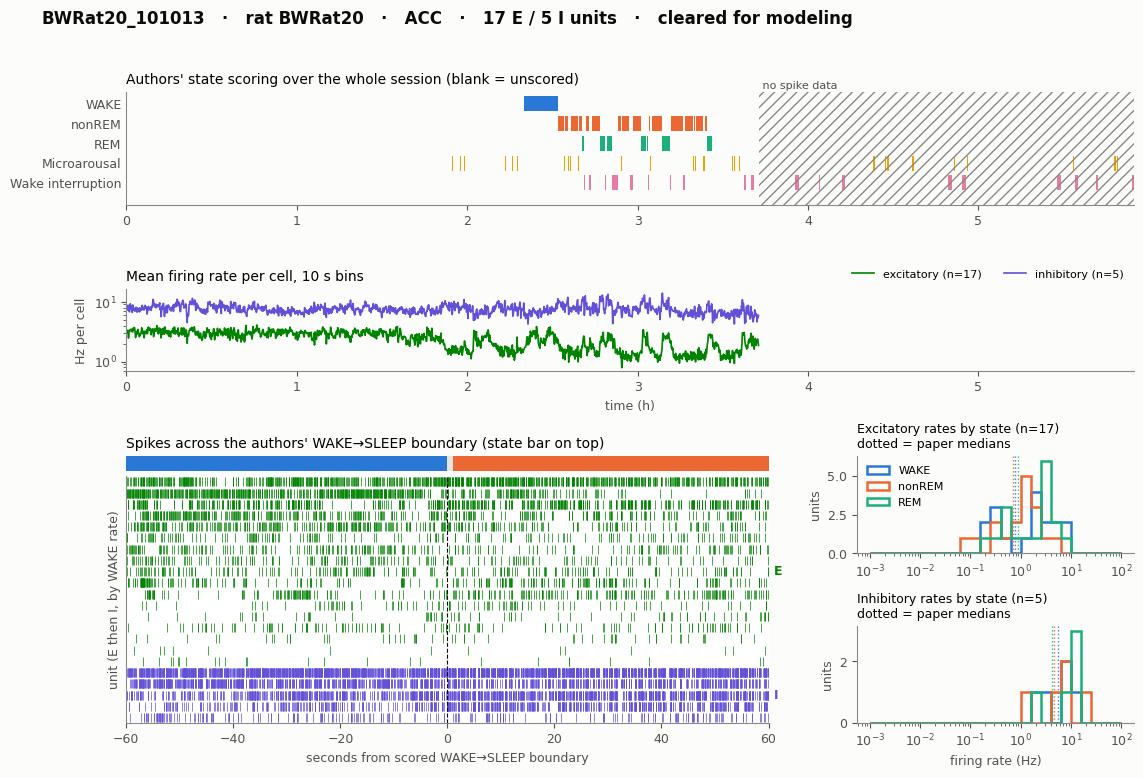

In [1]:
from IPython.display import Image, HTML, display
display(Image("../figures/qc/BWRat20_101013.png", width=1000))

**Preprocessing** (code in `src/`):

1. **Loaded as given.** Spike times, unit types and sleep-wake state intervals are the authors' values, unchanged.
2. **One label per second.** Every second of the recording gets a label, WAKE, nonREM or REM, if it lies inside one of the authors' sleep-wake state intervals. The authors left 47% of the recording unscored; those seconds, their microarousal and wake-interruption seconds, and the 0.7% of seconds where two intervals overlap are part of the input but never training targets.
3. **10 ms bins.** Each unit's spikes are counted in 10 ms bins over the whole recording.
4. **Relative counts.** Each unit's counts are divided by that unit's own mean count per bin over the recording (no labels involved). Firing rates differ several-fold between rats; with raw counts the network did not learn at all, with relative counts it did.

In [2]:
import pandas as pd
qc = pd.read_csv("../reports/qc_table.csv")
cols = {"session": "session", "rat": "rat name", "regions": "brain region", "n_E": "excitatory units", "n_I": "inhibitory units",
        "min_WAKE": "WAKE (min)", "min_nonREM": "nonREM (min)", "min_REM": "REM (min)", "pct_seconds_scored": "% scored"}
t = qc[list(cols)].rename(columns=cols).round(0)
t[list(cols.values())[5:]] = t[list(cols.values())[5:]].astype(int)
display(HTML(f"<p style='break-after: avoid'><b>Sessions used</b>: metadata for the {len(t)} sessions the model was trained and tested on.</p>" + t.set_index("session").to_html()))
display(HTML("<p><i>Each session is one recording of a rat's frontal-cortical activity across sleep and wake. "
             "% scored is the share of 1 s time points the authors labeled WAKE, nonREM or REM. "
             f"All {len(t)} sessions were cleared by my QC, which checked that every file loads and matches the authors' file list, "
             "spike times are sorted and lie within the recording, sleep-wake state intervals are well-formed, "
             "and unit counts and brain regions match the paper.</i></p>"))

,rat name,brain region,excitatory units,inhibitory units,WAKE (min),nonREM (min),REM (min),% scored
session,,,,,,,,
20140526_277um,B22,mPFC,51,11,36,46,3,50
20140527_421um,B22,mPFC,24,5,25,32,3,30
20140528_565um,B22,mPFC,27,6,13,46,9,42
BWRat17_121712,BWRat17,ACC,43,7,40,16,2,69
BWRat17_121912,BWRat17,ACC,34,1,20,42,4,85
BWRat18_020513,BWRat18,M2,34,6,34,69,10,97
BWRat19_032413,BWRat19,M2,37,13,31,29,0,86
BWRat19_032513,BWRat19,M2,51,10,8,18,4,62
BWRat20_101013,BWRat20,ACC,17,5,12,32,11,31


## 2. Objective

To decode a rat's sleep-wake state (WAKE, nonREM or REM) from its frontal-cortical spiking: train the model on rats' recordings, then test it on a rat it has never seen. The trained model can then be used to ask which cortical neurons and activity patterns carry information about the sleep-wake state.

Sleep and wake are switched by hypothalamic and brainstem circuits (Saper, Scammell & Lu 2005, *Nature* 437:1257). Frontal cortex sits downstream of that switch, so what the decoder reads is the cortical signature of the state, and the ablations ask which parts of that signature carry the most information.

## 3. Model

A 1D convolutional neural network that reads the neuronal spiking time series directly. The same small filters slide along every neuron's spike train, an attention layer compares neurons with each other at every 10 ms step, a learned pooling step merges them into one population signal, and three wider convolutions read how that signal evolves over the second before the readout. Every weight belongs to a filter or an attention layer that is shared by all neurons, so a network trained on nine rats runs on a tenth with a different number of cells.

I chose this over a feature-based classifier because the aim was to work with the activity itself rather than with a handful of numbers I would have picked, and over an LSTM or transformer because a recording of ten rats is too little data for models with many more weights. The logistic-regression baseline below shows what firing rates alone can do.

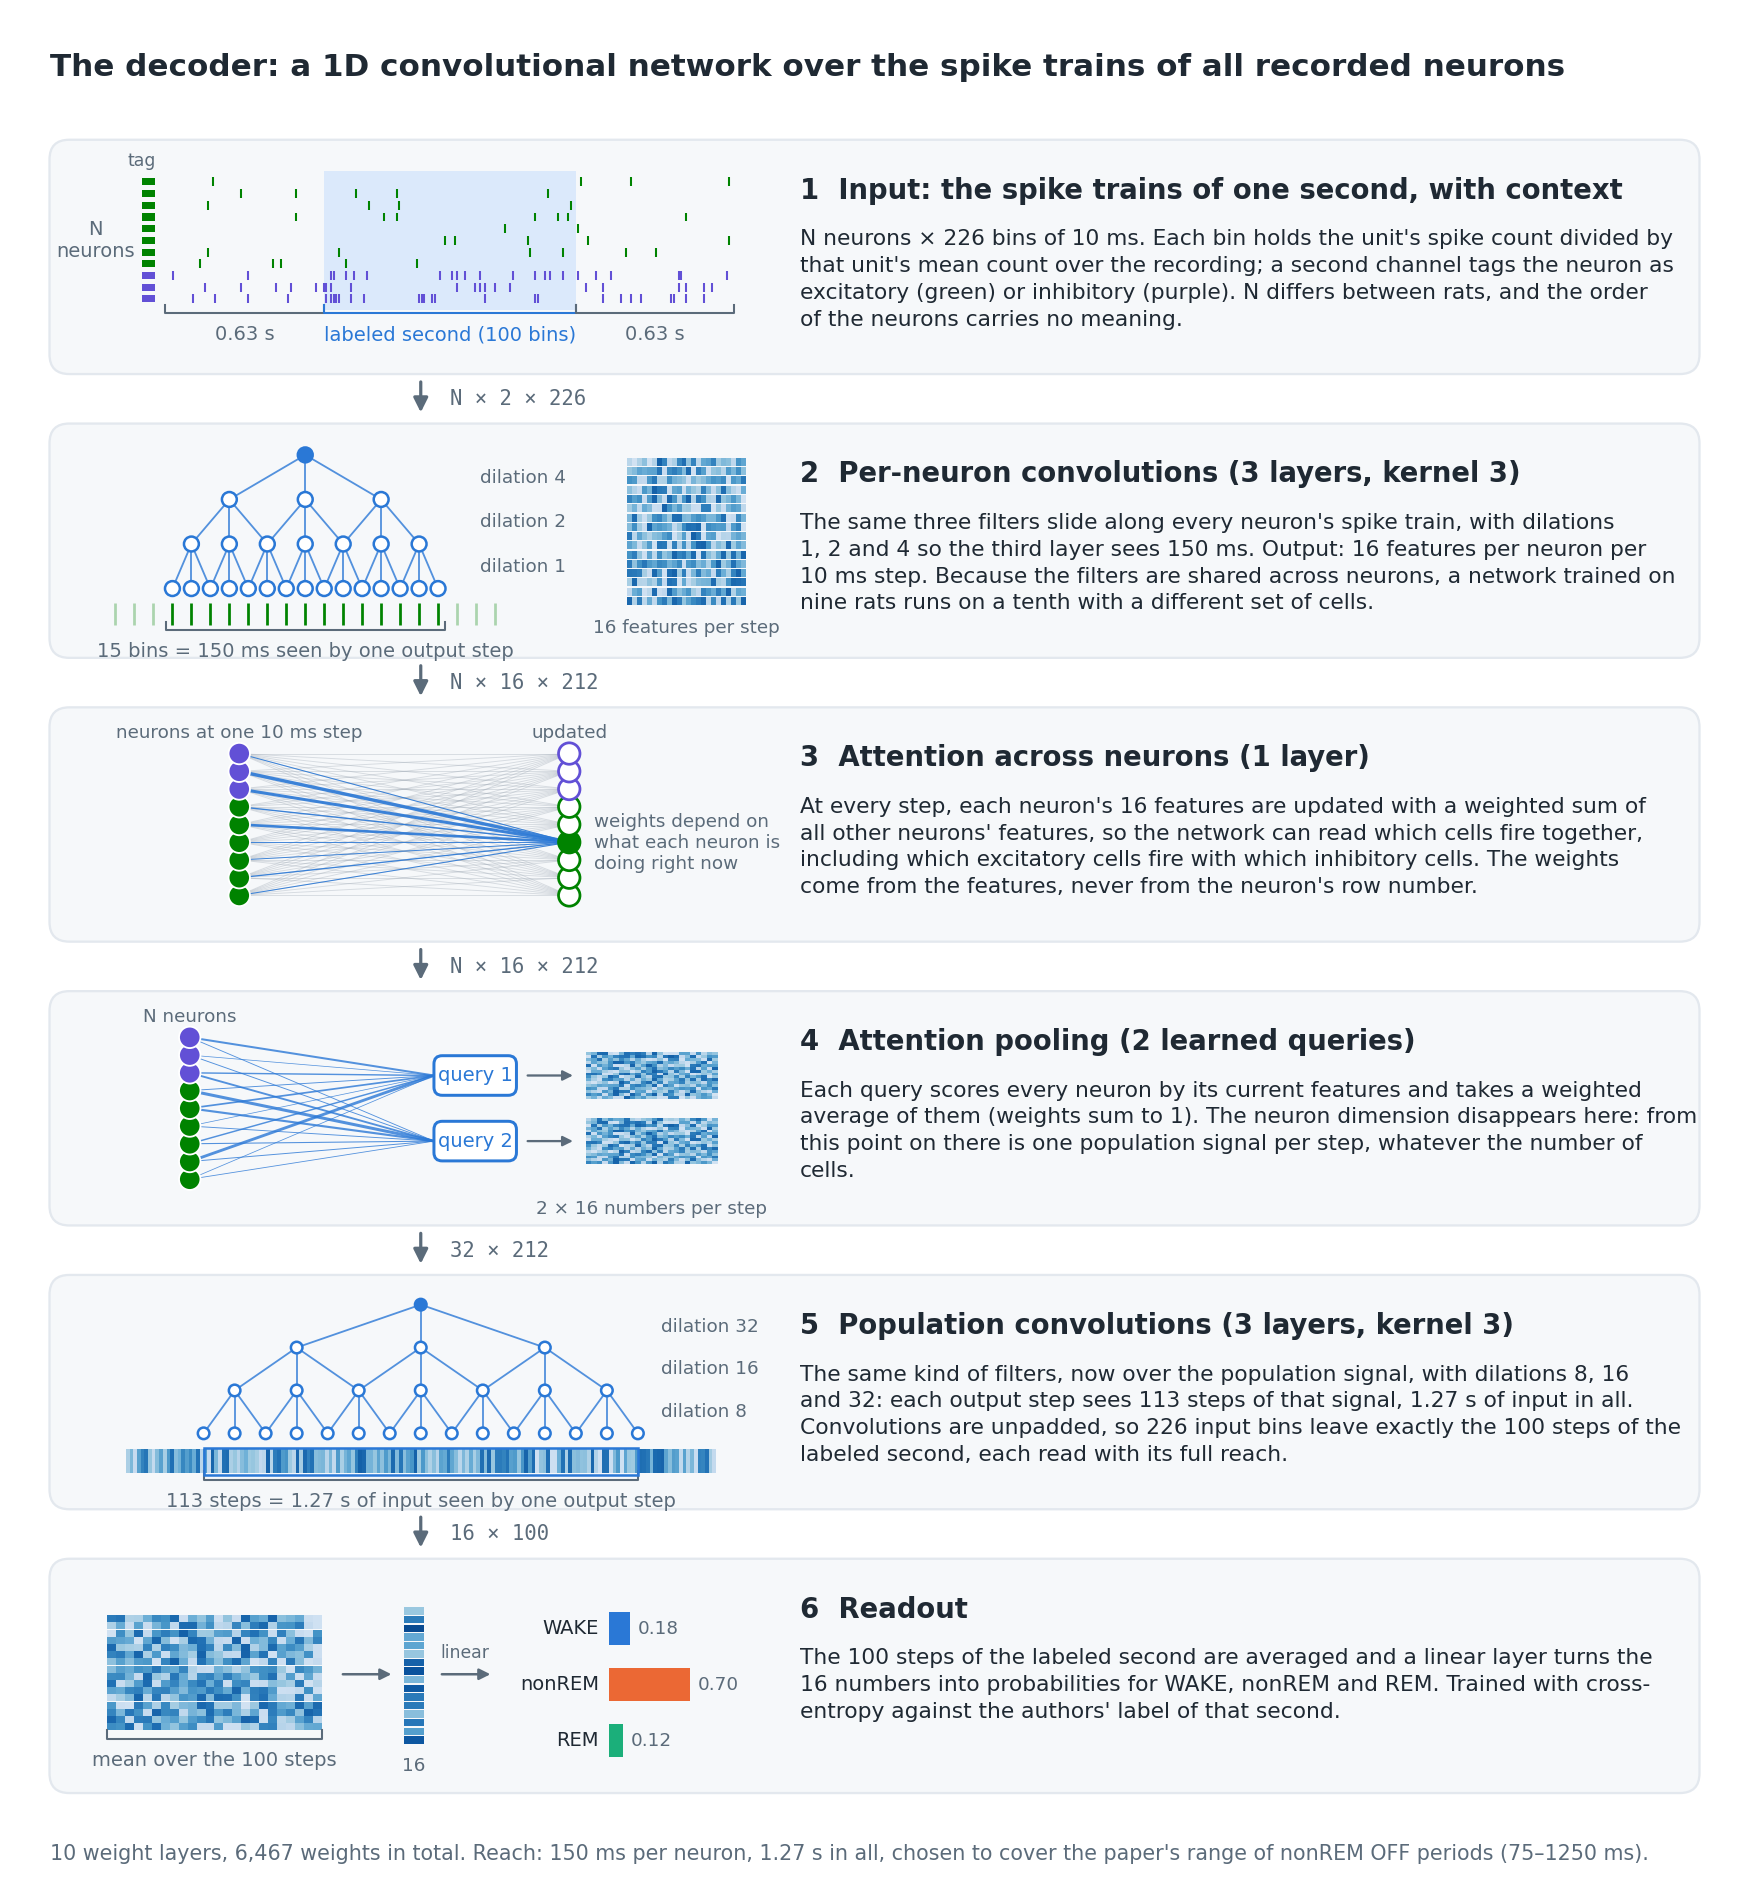

In [3]:
display(Image("../figures/architecture.png", width=950))

**Training and testing.** Leave-one-rat-out, ten folds: one test rat, one validation rat (for early stopping) and eight training rats, with a rat's sessions always kept together. Each epoch draws the same number of labeled seconds from every training rat and every state, so no rat and no state dominates. The loss is cross-entropy against the authors' label of each second. The network has 16 filters, 2 pooling queries and 6.5k weights.

A run that never left chance on its validation rat was restarted with a new random seed (3 of 28 shortened ablation runs; none of the ten main folds). The failed runs are kept in `results/` under `_collapsed`.

**Baseline.** Logistic regression on the same 2.26 s window, with the spike trains first collapsed to two traces: spikes per excitatory cell and per inhibitory cell in each bin. In practice it can only read overall excitatory and inhibitory firing rates.

## 4. Metric

* **Balanced accuracy** on the held-out rat: the mean over states of the fraction of each state's seconds that were called correctly. The large nonREM class (55% of labeled seconds) cannot inflate it. Chance is 0.33 for three states and 0.50 for two.
* **Cohen's kappa**: agreement with the authors' labels beyond chance, the standard figure in sleep scoring.
* Both are reported for the three states (WAKE / nonREM / REM) and for WAKE vs SLEEP (the same predictions with nonREM and REM merged into SLEEP), with a confusion matrix and results per rat.
* Every number below comes from rats the model never trained on.

## 5. Results

### 5.1 Decoding held-out rats

| model | WAKE / nonREM / REM: balanced accuracy (mean ± sd over rats) | kappa | WAKE vs SLEEP: balanced accuracy | kappa | rats |
|---|---|---|---|---|---|
| CNN on the spike trains | **0.52 ± 0.07** | 0.39 | **0.66 ± 0.14** | 0.28 | 10 |
| logistic regression on excitatory / inhibitory rates | 0.42 ± 0.07 | 0.16 | 0.57 ± 0.07 | 0.15 | 10 |

*WAKE / nonREM / REM is the 3-class decoder: the model names the state of each second as one of the three. WAKE vs SLEEP uses the same predictions with nonREM and REM counted as SLEEP.*

The CNN beats the baseline on the three-state score in 10 of 10 rats. Separating nonREM from the two activated states (WAKE and REM merged): CNN 0.80 ± 0.10, baseline 0.61 ± 0.08, better in 10 of 10 rats. Per-state recall of the CNN, averaged over rats: WAKE 0.47, nonREM 0.84, REM 0.25.

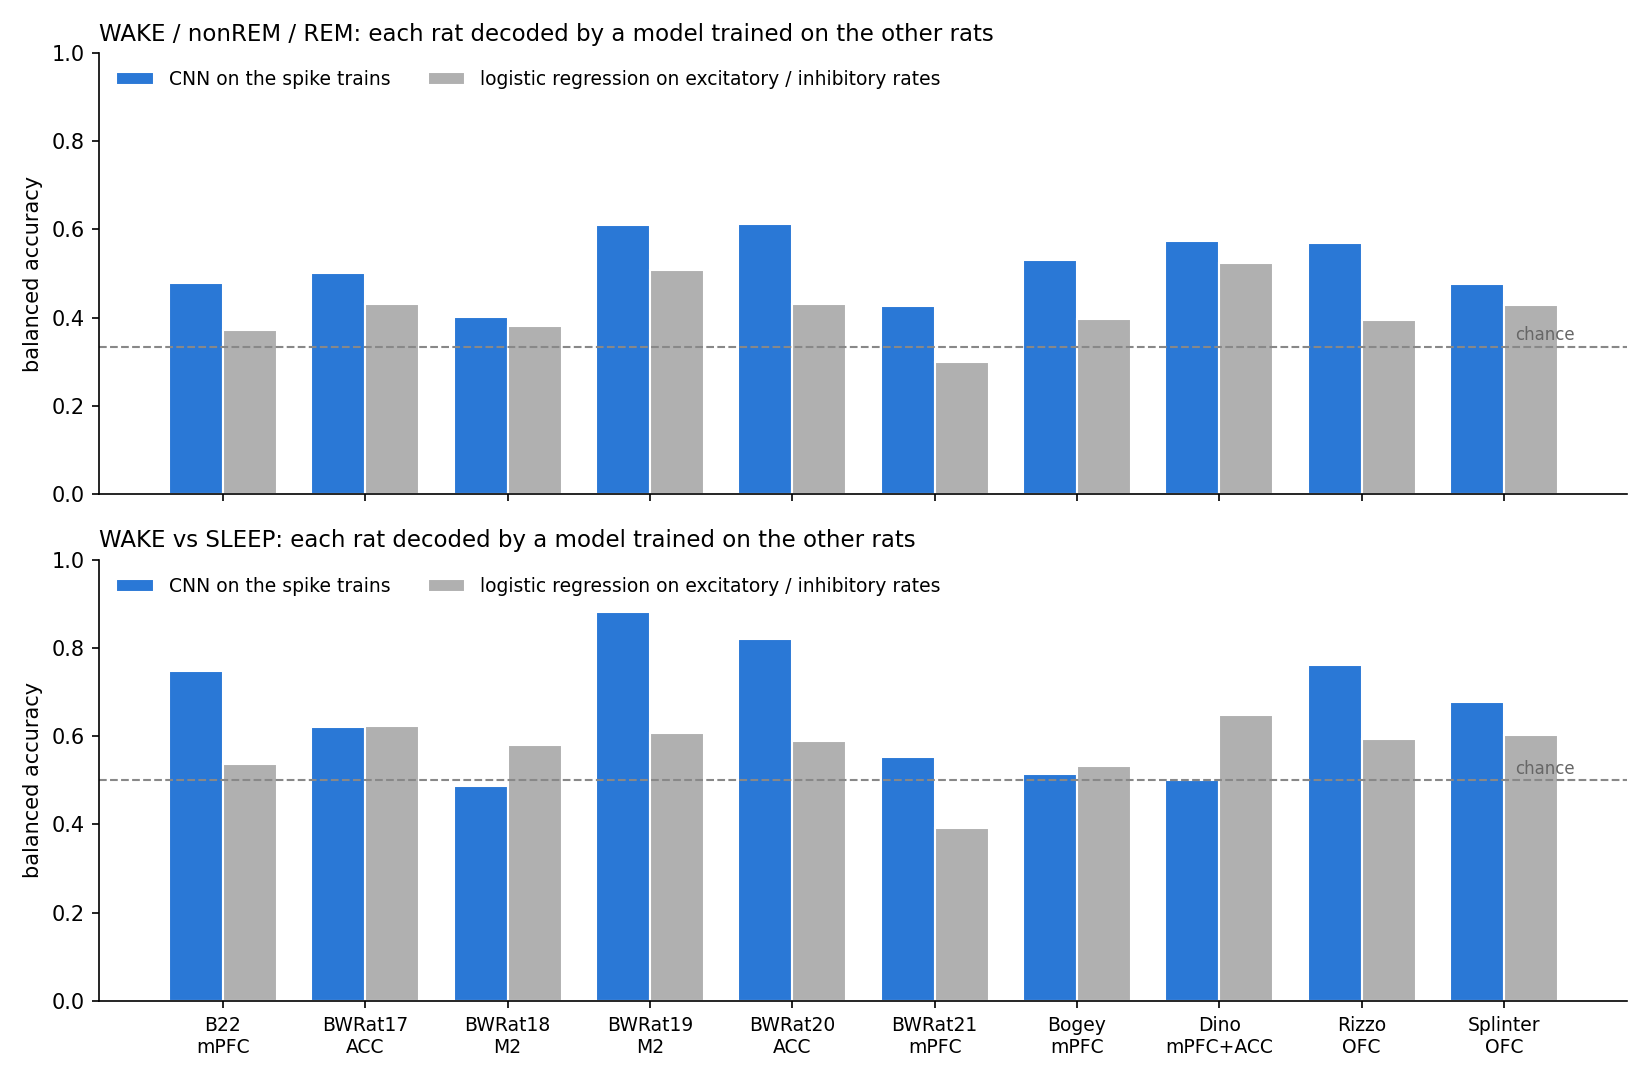

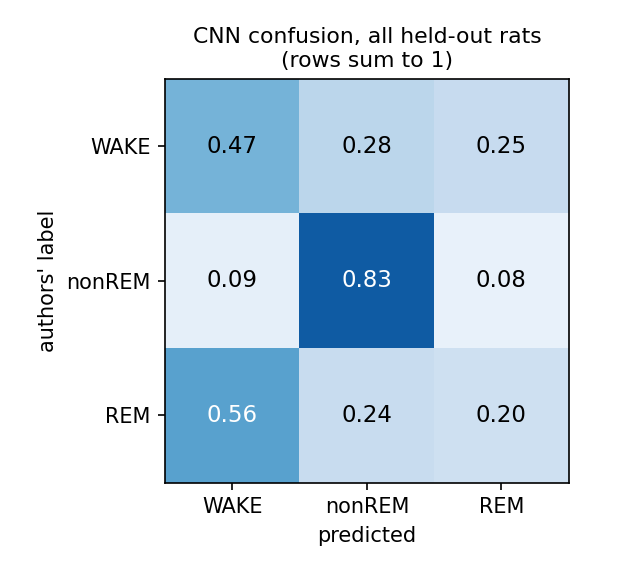

,,WAKE / nonREM / REM: logistic regression,WAKE / nonREM / REM: CNN,WAKE vs SLEEP: logistic regression,WAKE vs SLEEP: CNN
rat,region,,,,
B22,mPFC,0.37,0.48,0.54,0.75
BWRat17,ACC,0.43,0.50,0.62,0.62
BWRat18,M2,0.38,0.40,0.58,0.49
BWRat19,M2,0.51,0.61,0.61,0.88
BWRat20,ACC,0.43,0.61,0.59,0.82
BWRat21,mPFC,0.30,0.43,0.39,0.55
Bogey,mPFC,0.40,0.53,0.53,0.51
Dino,mPFC+ACC,0.52,0.57,0.65,0.50
Rizzo,OFC,0.40,0.57,0.59,0.76


In [4]:
display(Image("../figures/results_decoder.png", width=900))
display(Image("../figures/results_confusion.png", width=300))
folds = pd.read_csv("../results/summary_folds.csv")
d = folds[folds.experiment.isin(["decoder", "baseline"])]
show = d.pivot(index=["rat", "region"], columns="experiment", values=["balanced_accuracy", "bal_acc_2class"]).round(2)
show.columns = [f"{'WAKE / nonREM / REM' if a == 'balanced_accuracy' else 'WAKE vs SLEEP'}: {'CNN' if b == 'decoder' else 'logistic regression'}" for a, b in show.columns]
display(HTML("<p style='break-after: avoid'><b>Balanced accuracy per held-out rat</b></p>" + show.to_html()))

### 5.2 Ablations: which cells carry the state information?

Each ablation retrains the same network from scratch with something removed, on five held-out rats (one per brain region); the reference row is the full network trained the same way.

* **Excitatory cells only / inhibitory cells only**: the model sees only the cells of one type.
* **Excitatory cells, as many as inhibitory**: random subsets of excitatory cells, as many as the session has inhibitory cells (50 draws). This is the control for the excitatory vs inhibitory comparison, because inhibitory cells are far fewer (115 vs 856).
* **Without the population convolutions**: the pooled population signal goes straight to the readout, so the model cannot read how the population evolves over the second.

| model | WAKE / nonREM / REM balanced accuracy (mean ± sd) | rats |
|---|---|---|
| all cells (reference) | 0.54 ± 0.05 | 5 |
| excitatory cells only | 0.53 ± 0.06 | 5 |
| inhibitory cells only | 0.55 ± 0.07 | 5 |
| excitatory cells, as many as inhibitory | 0.44 ± 0.02 | 5 |
| without the population convolutions | 0.50 ± 0.12 | 5 |

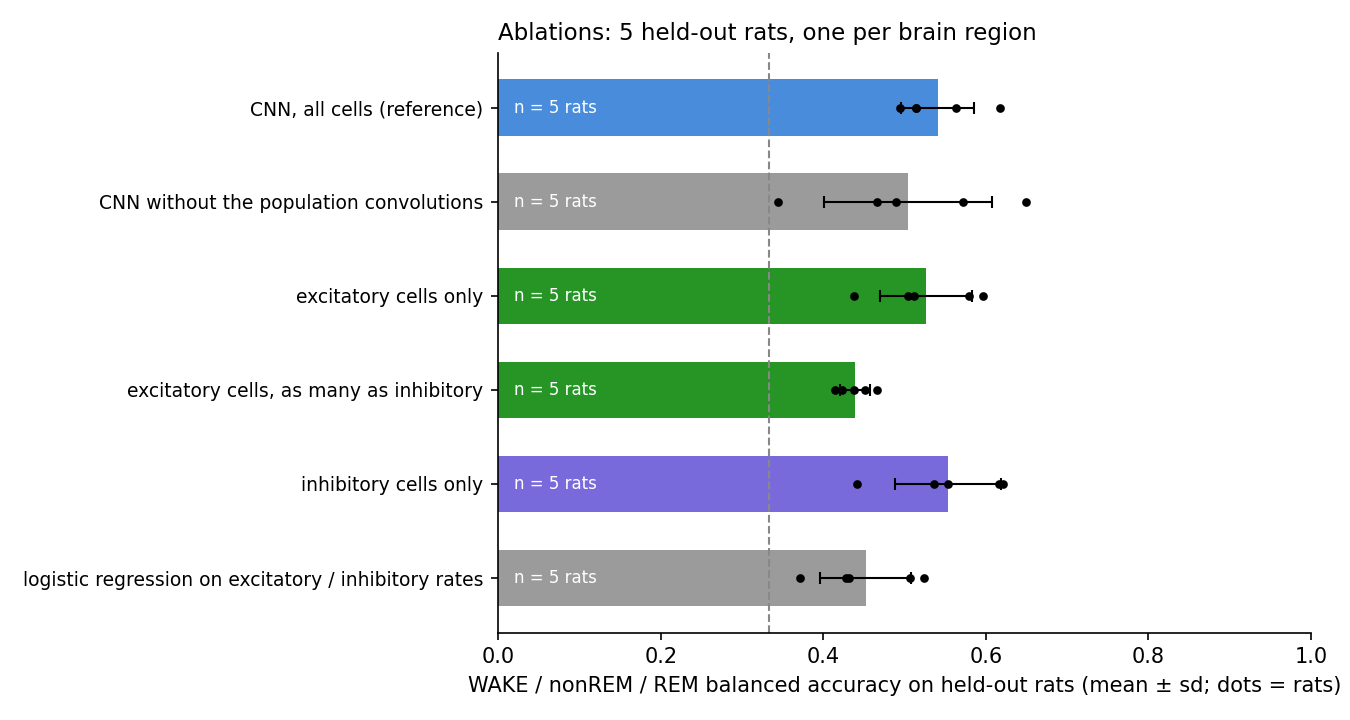

In [5]:
display(Image("../figures/results_ablations.png", width=850))
display(HTML("<p><i>All ablation runs and the reference used the same shortened training budget. "
             "Sessions with fewer than 3 inhibitory cells are skipped in the cell-type rows.</i></p>"))

### 5.3 Firing around state boundaries

The figure shows excitatory rate, inhibitory rate and population synchrony (the paper's measure: the fraction of excitatory cells firing within a 50 ms window) from 60 s before to 60 s after four kinds of boundary in the authors' scoring, as a percent change from each session's own baseline (−60 to −30 s); median and interquartile range across sessions. The boundaries:

* **Microarousal onset**: the start of a brief wake-like period (up to 40 s) inside nonREM sleep, as scored by the authors.
* **Wake-interruption onset**: the start of a longer wake-like period (40–120 s) during sleep.
* **WAKE → SLEEP** and **SLEEP → WAKE**: the authors' full state switches; only 25 and 3 events, so these two columns are descriptive.

Only microarousals and wake interruptions that directly follow scored sleep are included (227 and 288 events); the rest lie in unscored stretches, where no baseline state is defined. Changes are small (within ±15% of baseline) and no cell type reliably leads the scored boundary at 1 s resolution.

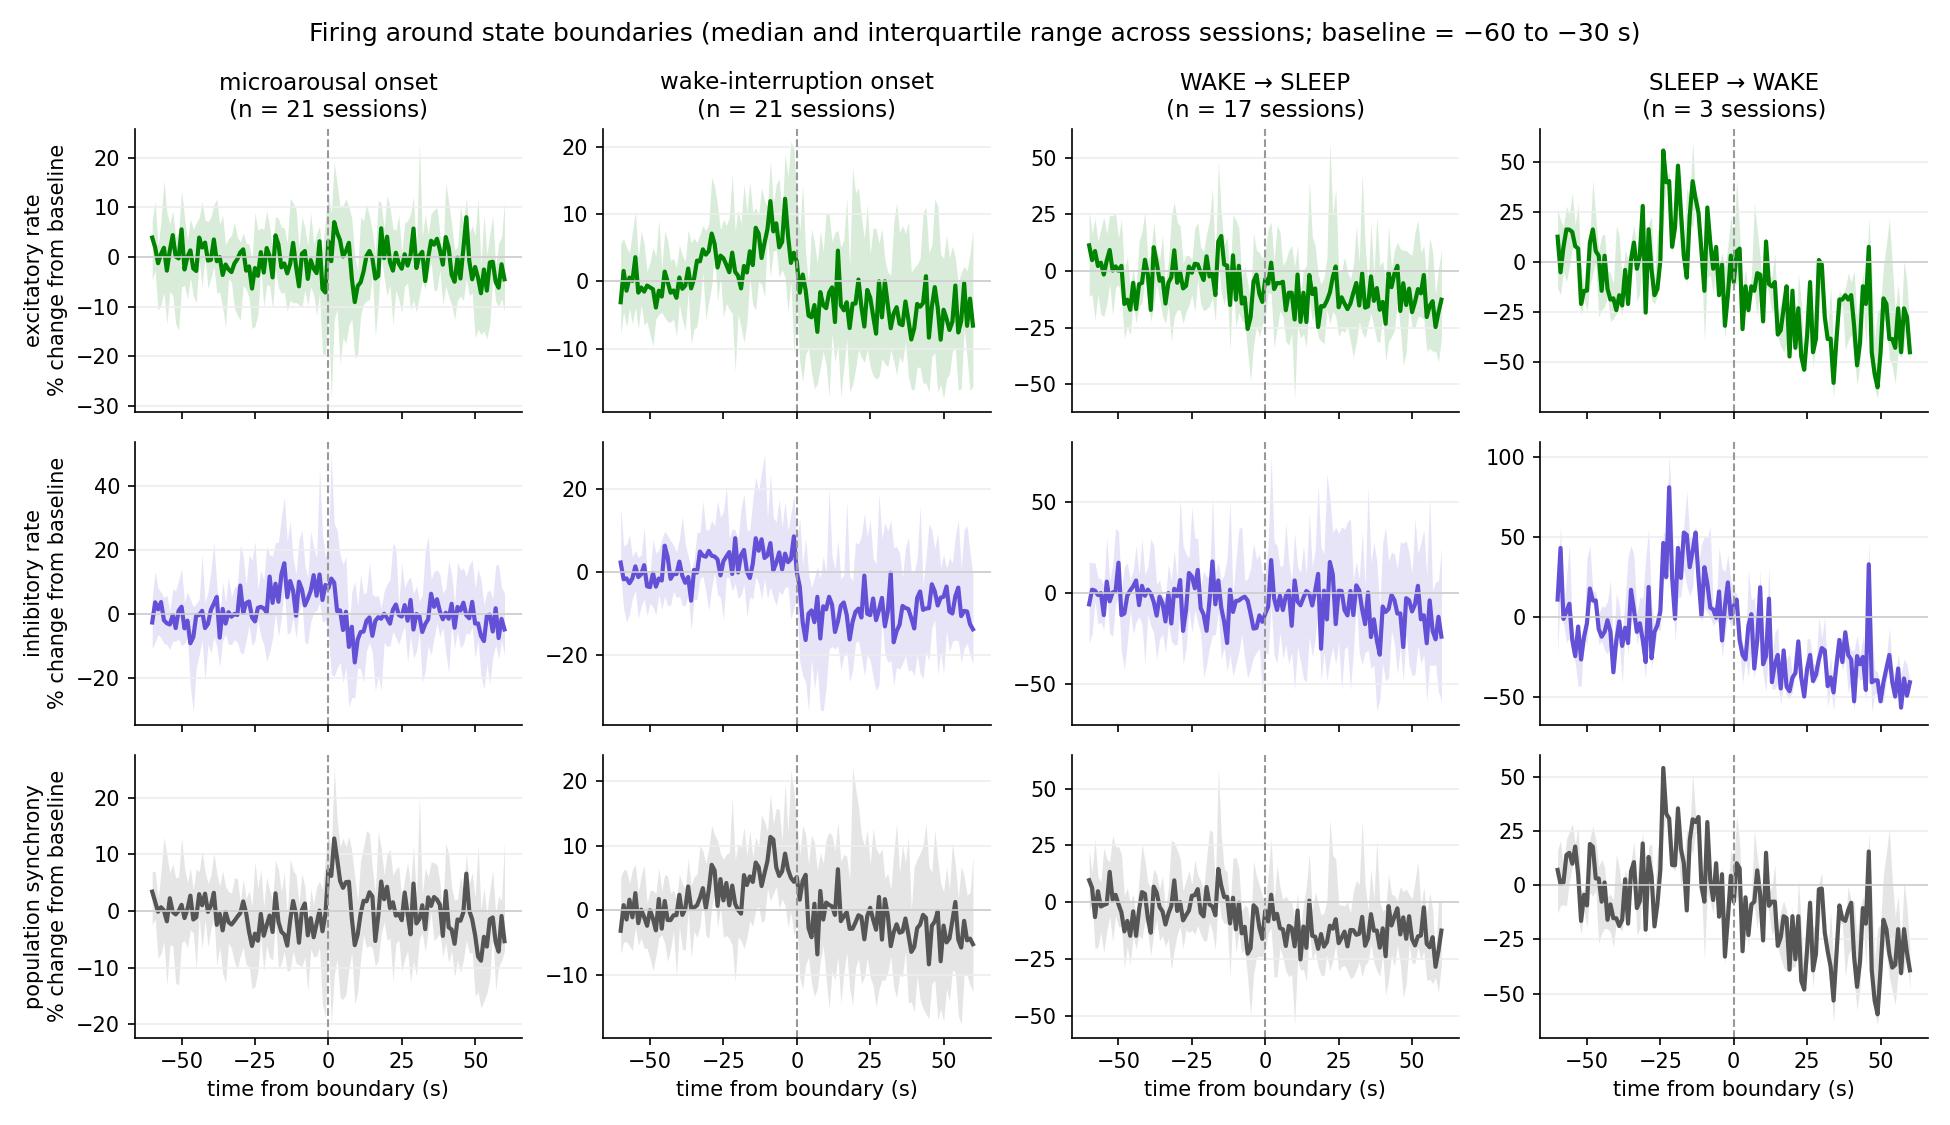

In [6]:
display(Image("../figures/transitions.png", width=1000))

### 5.4 3D model

A 3D model of the recorded neurons from the two Dino_061914 sessions: the same rat, recorded at the same time with one probe in the anterior cingulate cortex (ACC) and one in the medial prefrontal cortex (mPFC), across the authors' WAKE→SLEEP switch. Units are placed inside their region's volume in the BrainGlobe `whs_sd_rat_39um` rat atlas (mPFC → prelimbic and infralimbic areas; ACC → cingulate areas 1 and 2). Excitatory cells are green, inhibitory cells purple, and each marker swells with the spikes it fires. The strip below shows the authors' state and the decoder's prediction for each probe (Dino was the held-out rat). The two probes' predictions agree almost second by second, including the error: Dino's waking seconds are read as REM.

* Rotatable version: `results/brain3d/brain3d.html` (open in a browser; play button at the bottom left).
* Video: `results/brain3d/brain3d.mp4`.

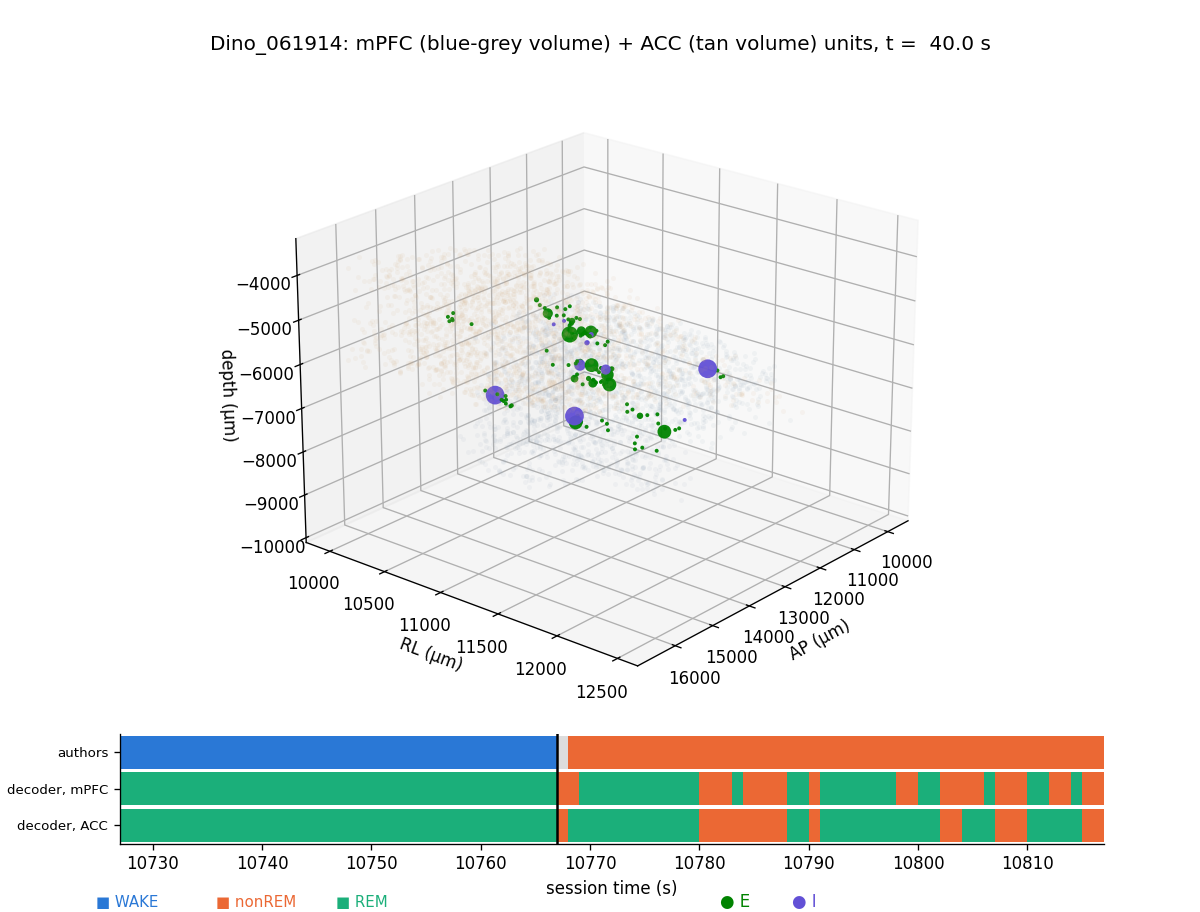

In [7]:
display(Image("../figures/brain3d_still.png", width=800))

## 6. Interpretation, limitations and improvements

**What the results show**

* Trained on other rats, the network scores a held-out rat at 0.52 balanced accuracy over WAKE / nonREM / REM (chance 0.33), against 0.42 for logistic regression on firing rates, and it wins in 10 of 10 rats.
* What transfers across rats is nonREM. Separating nonREM from the two activated states (WAKE and REM) reaches 0.80, above the baseline in 10 of 10 rats. nonREM has a signature visible in spikes alone: the alternation of population silence and activity (the paper's OFF periods).
* Telling WAKE from REM is the weak point (WAKE recall 0.47, REM recall 0.25). Both are activated cortex with similar firing; the authors themselves separated them with an EMG proxy, which the decoder never sees. The error depends on the rat: in 3 rats (BWRat18, Bogey, Dino) almost no waking second is called WAKE, most are called REM.
* Inhibitory cells alone decode as well as all cells (0.55 vs 0.54), while the same number of excitatory cells reaches only 0.44. A few inhibitory cells carry as much state information as the whole population, which matches the paper's finding that inhibitory firing tracks state most strongly.
* Removing the population convolutions changes the score by -0.04 (0.50 vs 0.54), within the rat-to-rat spread, so five rats cannot tell whether the population dynamics over the second add information.
* Around the authors' boundaries, firing changes are small and no cell type leads the boundary, consistent with a cortex that follows the subcortical switch rather than driving it.

**Limitations**

* *Information, not causation.* The ablations show which cells carry state information. Cortex is downstream of the hypothalamic-brainstem switch, so nothing here says what causes the state.
* *WAKE is the authors' scored WAKE*: arousals of 7 min or longer, during the lights-on period. Shorter arousals and the unscored 47% of the recording were never targets, so the decoder is untested on them.
* *Ten rats.* Each held-out rat is one data point, and brain region is confounded with rat (2–4 rats per region), so region differences cannot be separated from rat differences.
* *Schematic 3D positions.* The dataset gives region and shank, not coordinates.
* *One run per fold.* One random seed per fold, one network width, and shortened training for the ablations, to fit a laptop CPU.

**Improvements**

* Test the decoder against an independent measure of wakefulness, such as video or a separately recorded EMG, instead of a wake score derived from the LFP on the same probes as the spikes.
* Improve the network: 0.52 balanced accuracy leaves clear room. The width (16 filters) and the number of pooling queries (2) were never tuned and each fold was trained once, so a search over width, queries and seeds, with a longer training budget, is the first thing to try.
* Compare the learned per-neuron filters with the paper's OFF-period and spindle definitions, to see what the network actually picked up.

**References**

* Watson BO, Levenstein D, Greene JP, Gelinas JN, Buzsáki G (2016). Network homeostasis and state dynamics of neocortical sleep. *Neuron* 90:839. doi:10.1016/j.neuron.2016.03.036
* Dataset: CRCNS fcx-1, doi:10.6080/K02N506Q
* Saper CB, Scammell TE, Lu J (2005). Hypothalamic regulation of sleep and circadian rhythms. *Nature* 437:1257. doi:10.1038/nature04284